### Problem 1 : k-Nearest Neighbours & Naive Bayes - when forgetting is free

⏱️ ~20 min · 🧭 Stage 1 (Classical ML), rung 1 · 📄 `resources/papers/01-foundations/2015-cao-yang-towards-making-systems-forget.pdf`

> 🔗 **Building on ReadFIRST :** forgetting means *matching a model that never saw the data*. Here we meet the two
> easiest cases on the Ladder of Forgetting - rung 1.

We start where machine unlearning itself started. In 2015, Cao & Yang coined the term with a simple observation :

> *Many learning algorithms can be written as a function of **sums over the training data**. If a model is a sum, then
> forgetting a data point is a subtraction.*

In this notebook we meet two classical models where forgetting is **exact and essentially free** - and we will prove it
by comparing against a model that never saw the data. Then, in Problem 4, we will see why deep networks lose this
property, which is the reason the rest of the field exists.

| Model | What the "trained model" actually is | How to forget a row |
|---|---|---|
| **k-NN** | the training data itself | delete the row |
| **Gaussian Naive Bayes** | per-class counts, sums and sums of squares | subtract the row from those sums |

The data is the same "lab" used everywhere in this course : handwritten digits, where **Carol** contributed 40 digits
written with a thick marker and now asks to be forgotten (GDPR Art. 17 / DPDP s.12).

**TASK :** Make a k-NN classifier and a Naive Bayes classifier forget Carol, and prove they are now identical to models
that never saw her.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mul import lab, classical, viz
viz.style()

L = lab.make_lab("carol")
print(L, "\n", L.description)

Lab('carol': |D|=1257, |D_f|=40, |D_r|=1217, |test|=540) 
 Carol contributed 40 thick-marker digits and invokes her right to erasure.


----
### Part A : k-Nearest Neighbours

> 🟢 **In plain words :** k-NN does not really "learn". To classify a new digit, it looks up the *k* most similar
> training digits and lets them vote. The model **is** the training set. So the model doesn't just *remember* Carol -
> it literally contains her handwriting.

#### Step 1 : Train

In [2]:
# Step 1: 'train' k-NN (it just stores the data)
knn = classical.KNN(k=5).fit(L.X_train, L.y_train)

def acc(model, X, y):
    return float((model.predict(X) == y).mean())

print(f"k-NN accuracy on everyone's test digits     : {acc(knn, L.X_test, L.y_test):.1%}")
print(f"k-NN accuracy on Carol's own digits (D_f)    : {acc(knn, L.Xf, L.yf):.1%}")
print(f"k-NN accuracy on unseen thick-marker digits  : {acc(knn, L.X_like_forget, L.y_like_forget):.1%}")

k-NN accuracy on everyone's test digits     : 98.3%
k-NN accuracy on Carol's own digits (D_f)    : 75.0%
k-NN accuracy on unseen thick-marker digits  : 67.5%


#### Step 2 : Show the issue

Ask the model about a *new* thick-marker digit and look at **who it consults** to answer. If the neighbours are Carol's
digits, her data is directly shaping (and exposing) the prediction.

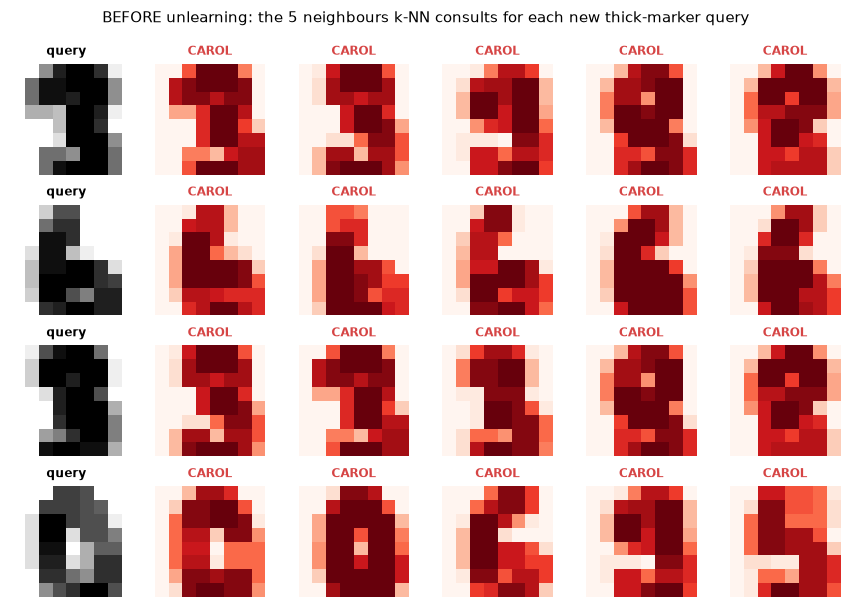

Share of all neighbours (for thick-marker queries) that are Carol's own digits: 85.8%


In [3]:
# Step 2: who does the model consult for a new thick-marker digit ?
query = L.X_like_forget[:4]
carol_rows = set(L.forget_idx.tolist())
nbrs = knn.neighbours(query)

fig, axes = plt.subplots(4, 6, figsize=(8, 5.6))
for i in range(4):
    axes[i, 0].imshow(query[i].reshape(8, 8), cmap="gray_r"); axes[i, 0].set_title("query", fontsize=8)
    for j, row in enumerate(nbrs[i]):
        is_carol = row in carol_rows
        axes[i, j + 1].imshow(L.X_train[row].reshape(8, 8), cmap="Reds" if is_carol else "gray_r")
        axes[i, j + 1].set_title("CAROL" if is_carol else "other", fontsize=8, color=viz.FORGET if is_carol else viz.INK)
for a in axes.ravel(): a.axis("off")
plt.suptitle("BEFORE unlearning: the 5 neighbours k-NN consults for each new thick-marker query", fontsize=10)
plt.tight_layout(); plt.show()

share_before = np.isin(knn.neighbours(L.X_like_forget), L.forget_idx).mean()
print(f"Share of all neighbours (for thick-marker queries) that are Carol's own digits: {share_before:.1%}")

That is the issue in its purest form: **Carol's raw data is inside the model and is used for every similar query.** Any
system that can show "similar examples" (recommendation explanations, retrieval, RAG) would literally show her
handwriting to other users.

#### Step 3 : Untrain

In [4]:
# Step 3: unlearn = mark Carol's rows as deleted
t0 = time.perf_counter()
knn_unlearned = classical.KNN(k=5).fit(L.X_train, L.y_train).unlearn(L.forget_idx)   # tombstone her rows
t_unlearn = time.perf_counter() - t0
print(f"Unlearning took {t_unlearn * 1e3:.2f} ms (including the copy).")

Unlearning took 0.15 ms (including the copy).


#### Step 4 : Show the result

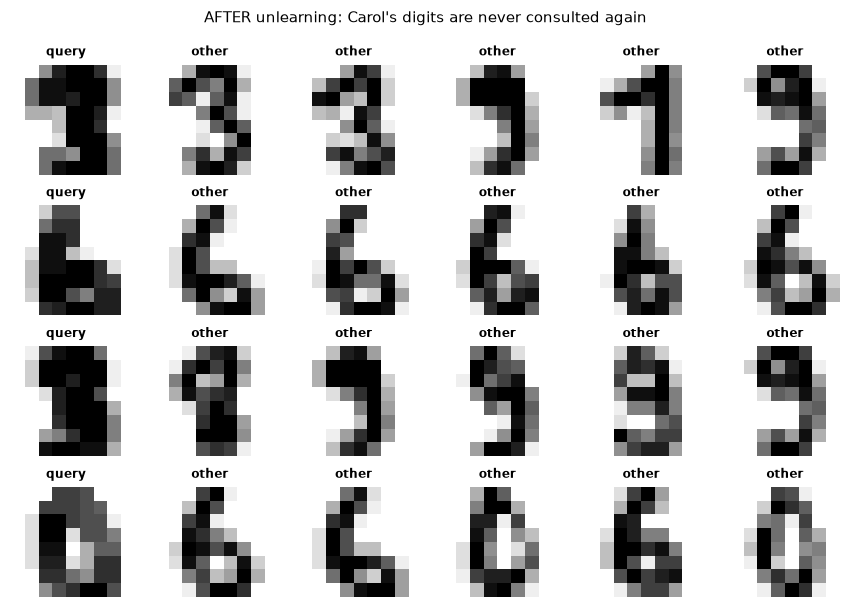

                                    before     after
Carol share of neighbours            85.8%      0.0%
accuracy on Carol digits (D_f)       75.0%     52.5%
accuracy on unseen thick digits      67.5%     62.5%


accuracy on test digits              98.3%     98.3%


In [5]:
nbrs_after = knn_unlearned.neighbours(query)
fig, axes = plt.subplots(4, 6, figsize=(8, 5.6))
for i in range(4):
    axes[i, 0].imshow(query[i].reshape(8, 8), cmap="gray_r"); axes[i, 0].set_title("query", fontsize=8)
    for j, row in enumerate(nbrs_after[i]):
        axes[i, j + 1].imshow(L.X_train[row].reshape(8, 8), cmap="gray_r"); axes[i, j + 1].set_title("other", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.suptitle("AFTER unlearning: Carol's digits are never consulted again", fontsize=10)
plt.tight_layout(); plt.show()

share_after = np.isin(knn_unlearned.neighbours(L.X_like_forget), L.forget_idx).mean()
print(f"{'':32s}{'before':>10s}{'after':>10s}")
print(f"{'Carol share of neighbours':32s}{share_before:10.1%}{share_after:10.1%}")
print(f"{'accuracy on Carol digits (D_f)':32s}{acc(knn, L.Xf, L.yf):10.1%}{acc(knn_unlearned, L.Xf, L.yf):10.1%}")
print(f"{'accuracy on unseen thick digits':32s}{acc(knn, L.X_like_forget, L.y_like_forget):10.1%}{acc(knn_unlearned, L.X_like_forget, L.y_like_forget):10.1%}")
print(f"{'accuracy on test digits':32s}{acc(knn, L.X_test, L.y_test):10.1%}{acc(knn_unlearned, L.X_test, L.y_test):10.1%}")

#### Step 5 : Prove it

The proof is the definition of exact unlearning: the unlearned model must behave **identically** to a model built
without Carol from the start.

In [6]:
# Step 5: the gold standard - a k-NN that never saw Carol
knn_never_saw_carol = classical.KNN(k=5).fit(L.Xr, L.yr)
X_all = np.r_[L.X_train, L.X_test, L.X_like_forget]
same = (knn_unlearned.predict(X_all) == knn_never_saw_carol.predict(X_all)).mean()
print(f"Predictions identical to a model that never saw Carol, on {len(X_all)} inputs: {same:.1%}")

Predictions identical to a model that never saw Carol, on 1877 inputs: 100.0%


✅ **Exact.** 100% identical, in milliseconds.

> 🔴 **For practitioners :** k-NN's exactness only holds for the k-NN *index*. Real systems copy data into places a
> tombstone does not reach: approximate-nearest-neighbour indices (HNSW/IVF graphs are built *using* the data and may
> need rebuilding or tombstone-aware search), caches, replicas, backups, and - crucially - any **embedding model that was
> fine-tuned** on the same data. For RAG systems, deleting a document from the vector store is the k-NN case; deleting
> it from the fine-tuned encoder or LLM is the deep-learning case of Problems 4-15.

----
### Part B : Gaussian Naive Bayes - forgetting by subtraction

> 🟢 **In plain words :** Naive Bayes learns, for each digit, the *average* brightness of every pixel and how much it
> varies. An average is just "sum ÷ count". If the model keeps the **sums and counts**, removing Carol means subtracting
> her pixels from the sums and her digits from the counts. Nothing else to do.

> 🔴 **For practitioners :** per class `c` we keep the sufficient statistics `n_c`, `S1_c = Σ x`, `S2_c = Σ x²`. Then
> `μ_c = S1_c / n_c` and `σ²_c = S2_c / n_c − μ_c²`. Any learner whose fit is a function of `Σᵢ g(xᵢ, yᵢ)` (Kearns' *statistical
> query* learners) admits this O(1)-per-point exact deletion - that is Cao & Yang's "summation form".

#### Step 1 : Train

In [7]:
gnb = classical.GaussianNB(var_smoothing=1e-2).fit(L.X_train, L.y_train)
print("The entire 'model' is three arrays:")
print("  n  (count per class)        ", gnb.n.shape, "->", gnb.n.astype(int))
print("  S1 (sum of pixels per class)", gnb.S1.shape)
print("  S2 (sum of squares)         ", gnb.S2.shape)
print(f"\naccuracy  test {acc(gnb, L.X_test, L.y_test):.1%} | Carol {acc(gnb, L.Xf, L.yf):.1%} | unseen thick {acc(gnb, L.X_like_forget, L.y_like_forget):.1%}")

The entire 'model' is three arrays:
  n  (count per class)         (10,) -> [124 127 124 128 127 127 127 125 122 126]
  S1 (sum of pixels per class) (10, 64)
  S2 (sum of squares)          (10, 64)

accuracy  test 91.1% | Carol 60.0% | unseen thick 61.3%


#### Step 2 : Show the issue

Where is Carol inside these numbers? Compare the class means learned **with** her and **without** her. The difference is
her fingerprint in the parameters.

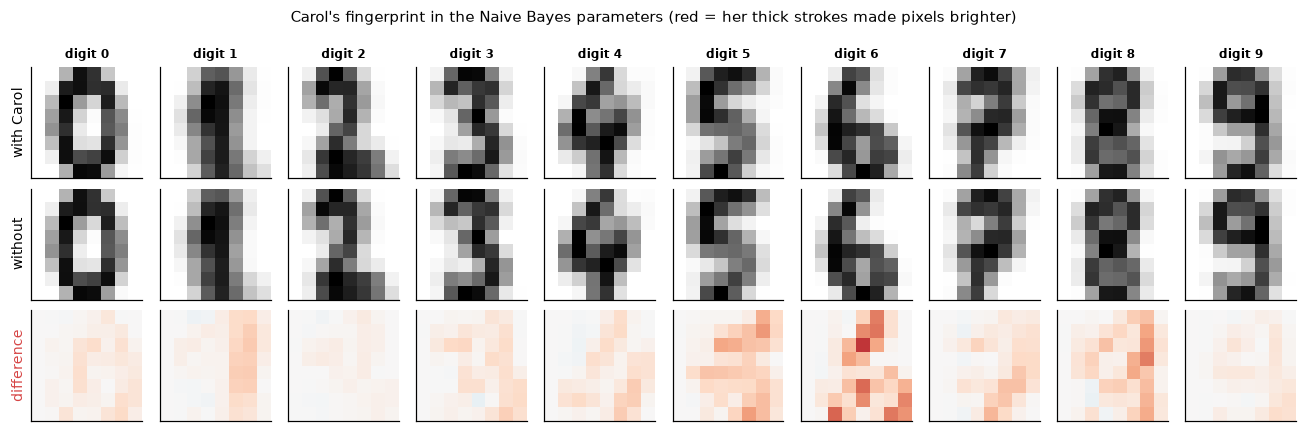

In [8]:
gnb_without = classical.GaussianNB(var_smoothing=1e-2).fit(L.Xr, L.yr)
mu_with = gnb.S1 / gnb.n[:, None]
mu_without = gnb_without.S1 / gnb_without.n[:, None]

fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for c in range(10):
    axes[0, c].imshow(mu_with[c].reshape(8, 8), cmap="gray_r"); axes[0, c].set_title(f"digit {c}", fontsize=8)
    axes[1, c].imshow(mu_without[c].reshape(8, 8), cmap="gray_r")
    axes[2, c].imshow((mu_with[c] - mu_without[c]).reshape(8, 8), cmap="RdBu_r", vmin=-0.08, vmax=0.08)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("with Carol", fontsize=9); axes[1, 0].set_ylabel("without", fontsize=9)
axes[2, 0].set_ylabel("difference", fontsize=9, color=viz.FORGET)
plt.suptitle("Carol's fingerprint in the Naive Bayes parameters (red = her thick strokes made pixels brighter)", fontsize=10)
plt.tight_layout(); plt.show()

The bottom row is small but clearly structured: Carol's thicker strokes brightened the edges of every digit's average.
Delete her rows from the database and those numbers stay in the model.

#### Step 3 : Untrain (subtract)

In [9]:
t0 = time.perf_counter()
gnb.unlearn(L.Xf, L.yf)                       # n -= 1, S1 -= x, S2 -= x² for each of Carol's digits
t_sub = time.perf_counter() - t0

t0 = time.perf_counter()
classical.GaussianNB(var_smoothing=1e-2).fit(L.Xr, L.yr)
t_refit = time.perf_counter() - t0
print(f"unlearn by subtraction : {t_sub * 1e3:7.2f} ms   (cost grows with |D_f|)")
print(f"refit from scratch     : {t_refit * 1e3:7.2f} ms   (cost grows with |D_r| - imagine a billion rows)")

unlearn by subtraction :    0.09 ms   (cost grows with |D_f|)
refit from scratch     :    0.49 ms   (cost grows with |D_r| - imagine a billion rows)


#### Step 4 : Show the result, and Step 5 : Prove it

In [10]:
gnb_before = classical.GaussianNB(var_smoothing=1e-2).fit(L.X_train, L.y_train)   # a fresh 'before' copy
print(f"{'':34s}{'before':>9s}{'after':>9s}{'never saw Carol':>17s}")
for name, X, y in [("accuracy on Carol digits (D_f)", L.Xf, L.yf),
                   ("accuracy on unseen thick digits", L.X_like_forget, L.y_like_forget),
                   ("accuracy on test digits", L.X_test, L.y_test)]:
    print(f"{name:34s}{acc(gnb_before, X, y):9.1%}{acc(gnb, X, y):9.1%}{acc(gnb_without, X, y):17.1%}")

diff = np.abs(gnb.predict_log_proba(X_all) - gnb_without.predict_log_proba(X_all)).max()
print(f"\nLargest difference in any predicted log-probability vs the never-saw-Carol model: {diff:.2e}")

                                     before    after  never saw Carol
accuracy on Carol digits (D_f)        60.0%    27.5%            27.5%
accuracy on unseen thick digits       61.3%    37.5%            37.5%
accuracy on test digits               91.1%    90.9%            90.9%

Largest difference in any predicted log-probability vs the never-saw-Carol model: 0.00e+00


✅ **Exact** - the unlearned model and the never-saw-Carol model agree perfectly (a difference of at most ~1e-12 is
possible from floating-point round-off; here it is exactly zero).

Two more things to notice in that table :

1. **Naive Bayes barely memorised Carol.** Its "before" accuracy on *her* digits is the same as on *unseen* thick-marker
   digits. Models that summarise data into averages memorise little - deep networks (Problem 4) memorise much more.
2. **Forgetting Carol made the model worse for everyone who writes like her** (unseen thick digits drop sharply). She was
   the only source of that style. This is a real Responsible-AI side effect: when the people who ask to be forgotten are
   not a random sample, unlearning can **degrade the model for an under-represented group**. Problem 12 measures this
   with fairness metrics on census data.

----
### Part C : The trap - preprocessing remembers too

> 🔴 **For practitioners :** the model is not the only thing fitted on the data. A `StandardScaler` stores means and
> standard deviations; a TF-IDF vectoriser stores document frequencies and a *vocabulary* (which can contain a person's
> name or a rare word only they used); PCA stores components; feature selection stores which features survived. All of
> these are **fitted on D**, so all of them carry D_f's influence.

In [11]:
from sklearn.preprocessing import StandardScaler
sc_with = StandardScaler().fit(L.X_train)
sc_without = StandardScaler().fit(L.Xr)
shift = np.abs(sc_with.mean_ - sc_without.mean_).max()
print(f"StandardScaler fitted with vs without Carol - largest change in a stored mean: {shift:.4f}")
print("-> if your pipeline scales data, the SCALER must be unlearned too (it is also a summation-form model!).")

StandardScaler fitted with vs without Carol - largest change in a stored mean: 0.0171
-> if your pipeline scales data, the SCALER must be unlearned too (it is also a summation-form model!).


The fix is the same trick: scalers, counts and vocabularies are sums too, so keep their sufficient statistics and
subtract. The lesson is organisational: **an unlearning request must cover the whole pipeline**, not just the final
model.

----
#### OUTCOME :

| Model | What it stores | How it forgot Carol | Proof | Cost |
|---|---|---|---|---|
| k-NN | the rows themselves | delete (tombstone) her rows | 100% identical predictions | ~0.1 ms |
| Naive Bayes | counts and sums | subtract her rows | identical log-probabilities | ~0.1 ms |

Both are **exact** and essentially **free**. Hold on to *why* : in both models, every training point contributes its
own separate term, so its contribution can be taken back out. Every rung above this one breaks that property a little
more.

#### Key Takeaways :

- **k-NN**: the model *is* the data → deleting the row is exact unlearning. But indices, caches and fine-tuned encoders
  must be handled too.
- **Naive Bayes** (and any *summation-form* model): keep counts and sums → unlearning is a subtraction, exact to
  floating-point precision, in milliseconds.
- Exact unlearning is proven by comparing with a model **that never saw the data** - here they are identical.
- **Preprocessing is a model too.** Scalers, vocabularies and IDF weights must be unlearned with the model.

#### TASK :
1. Increase `k` in k-NN from 5 to 25. Does Carol's share of neighbours before unlearning go up or down? Why?
2. After 10,000 add/subtract cycles, floating-point error can accumulate in `S2` (catastrophic cancellation). Write a
   loop that repeatedly `unlearn`s and re-adds Carol, and plot the max difference from a fresh fit. When would you
   schedule a periodic "refresh" refit?
3. scikit-learn's `GaussianNB` sets its smoothing as `var_smoothing × max(variance of all features)` - computed on the
   **whole** training set. Explain why that makes subtraction-based unlearning *not quite* exact for sklearn's version,
   and how our implementation avoids it.
4. Implement unlearning for `StandardScaler` using running sums, and verify it matches a refit on `D_r`.

#### ❓ Open question → Problem 2
Both models here were **independent sums**: every training point added its own term, so we could take it back out.
But most models do something *with* the sums - linear regression multiplies by a matrix **inverse**, so every point is
coupled to every other. And logistic regression has no formula at all: its weights are defined only as "the place where
the gradient is zero". **Can we still subtract a point when the model is not a plain sum?** That is rung 2.